# Smart Outcome Predictor


## Part A: Conceptual Foundation (Theory)

### 1. What are Ensemble Learning Methods and why they are effective?

Ensemble learning means using more than one model together. One model can make mistake, but many models can give a better final answer. It often improves accuracy and makes result more stable.

### 2. Difference between Bagging, Boosting and Voting

- **Bagging:** many models are trained separately on random bootstrap samples. Final answer is by vote or average.
- **Boosting:** models are trained one after another. Next model tries to correct earlier mistakes.
- **Voting:** different ready models give their answer. The final answer is based on majority vote or average probability.

### 3. Bias-Variance Trade-off

High bias means model is too simple and misses pattern. High variance means model learns too much from training data and may not work good on new data. Bagging mostly reduces variance. Boosting can reduce bias, but too much boosting can overfit.

### 4. Voting Classifier and Stacking Ensemble

A voting classifier combines prediction from different classifiers. Hard voting counts class votes. Soft voting uses class probabilities.

Stacking also combines models, but it uses one more model called a **meta-model**. The meta-model learns how to use predictions from base models.

### 5. AdaBoost, Gradient Boosting, LightGBM and XGBoost

- **AdaBoost:** gives more focus to wrongly predicted rows in next round.
- **Gradient Boosting:** adds small trees step by step to reduce errors.
- **LightGBM:** a fast gradient boosting library. It is useful for bigger data.
- **XGBoost:** another strong boosting library. It has regularization, so it tries to control overfitting.

## Part B: Dataset Understanding and Preparation

### 6. Features and target variables

For classification, target is `completion_status` (0 = not completed, 1 = completed).  
For regression, target is `final_score` (0 to 100).

All other useful columns are features. I will not use `student_id` because it is only an ID. I also remove both target columns from features, otherwise it can cause data leakage.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor, AdaBoostClassifier,
                              AdaBoostRegressor, GradientBoostingClassifier,
                              GradientBoostingRegressor, RandomForestClassifier,
                              RandomForestRegressor, VotingClassifier,
                              StackingClassifier, StackingRegressor)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, mean_squared_error,
                             r2_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier, XGBRegressor

# same random state is used again and again for fair result
RANDOM_STATE = 42

In [9]:
# load the CSV file
data = pd.read_csv("Smart_Outcome_Predictor_Dataset.csv")

print("Data shape:", data.shape)
data.head()

Data shape: (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [10]:
# basic data check
print(data.info())
print("\nMissing values:")
print(data.isnull().sum())

print("\nClass count for completion_status:")
print(data["completion_status"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   country_region         5200 non-null   object 
 3   device_type            5200 non-null   object 
 4   education_background   5200 non-null   object 
 5   course_level           5200 non-null   object 
 6   course_category        5200 non-null   object 
 7   course_start_date      5200 non-null   object 
 8   week_of_year           5200 non-null   int64  
 9   sessions               5200 non-null   int64  
 10  time_spent_hours       5088 non-null   float64
 11  videos_watched         5200 non-null   int64  
 12  quiz_attempts          5200 non-null   int64  
 13  assignments_submitted  5200 non-null   int64  
 14  forum_posts            5200 non-null   int64  
 15  avg_

### 7. Train-test split

I kept 80% data for training and 20% data for testing. The class target is stratified, so both classes stay in train and test data.

### 8. Basic preprocessing

Some numeric columns have missing values, so I fill them with median. Text columns are changed to numbers using one-hot encoding. Numeric data is scaled. Date column is made into month and day columns.

In [11]:
# Make simple date features from course_start_date
# errors="coerce" means bad date will become missing instead of stopping code
data["course_start_date"] = pd.to_datetime(data["course_start_date"], errors="coerce")
data["start_month"] = data["course_start_date"].dt.month
data["start_day"] = data["course_start_date"].dt.day

# Targets
# completion_status is for classification
# final_score is for regression
y_class = data["completion_status"]
y_reg = data["final_score"]

# I dropped ID, old date and both target columns
X = data.drop(columns=["student_id", "course_start_date", "completion_status", "final_score"])

print("Features used:")
print(X.columns.tolist())
print("\nNumber of features before encoding:", X.shape[1])

Features used:
['age', 'country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'start_month', 'start_day']

Number of features before encoding: 17


In [12]:
# one split is used for both problems
X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
    X, y_class, y_reg,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_class
)

print("Train rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Train rows: 4160
Test rows: 1040


In [13]:
# columns are divided into numeric and text columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric columns:", num_cols)
print("Text columns:", cat_cols)

num_pipe = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_pipe = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("number", num_pipe, num_cols),
    ("text", cat_pipe, cat_cols)
])

# only to see that preprocessing is working
X_train_ready = preprocessor.fit_transform(X_train)
print("Features after preprocessing:", X_train_ready.shape[1])

Numeric columns: ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
Text columns: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
Features after preprocessing: 30


## Small helper functions for evaluation

### 28. Classification metrics

I use accuracy, precision, recall, F1-score and ROC-AUC. F1 is helpful when we want balance between precision and recall.

### 29. Regression metrics

I use MAE, RMSE and R-square. Smaller MAE/RMSE is better. Higher R-square is better.

In [14]:
# Empty lists will save results from all models
class_results = []
reg_results = []

def save_class_result(name, y_true, y_pred, y_prob=None):
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    }
    class_results.append(row)
    print(name, "accuracy =", round(row["Accuracy"], 4))

def save_reg_result(name, y_true, y_pred):
    row = {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R-square": r2_score(y_true, y_pred)
    }
    reg_results.append(row)
    print(name, "MAE =", round(row["MAE"], 4), "R-square =", round(row["R-square"], 4))

## Part C: Bagging (Bootstrap Aggregating)

### 9. Bagging Classifier

Bagging makes many decision trees using different random samples. Final class is based on vote.

In [15]:
# 9. Bagging classifier
bag_clf = Pipeline([
    ("prep", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=80,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

bag_clf.fit(X_train, y_class_train)
bag_class_pred = bag_clf.predict(X_test)
bag_class_prob = bag_clf.predict_proba(X_test)[:, 1]
save_class_result("Bagging Classifier", y_class_test, bag_class_pred, bag_class_prob)

Bagging Classifier accuracy = 0.7048


### 10. Bagging Regressor

For final score, bagging takes average of trees instead of voting.

In [16]:
# 10. Bagging regressor
bag_reg = Pipeline([
    ("prep", preprocessor),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
        n_estimators=80,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

bag_reg.fit(X_train, y_reg_train)
bag_reg_pred = bag_reg.predict(X_test)
save_reg_result("Bagging Regressor", y_reg_test, bag_reg_pred)

Bagging Regressor MAE = 8.2934 R-square = 0.4139


### 11. Bagging vs single decision tree

A single decision tree can change a lot if data changes. Bagging averages many trees, so usually it is more stable. I compare both below.

In [17]:
# simple single tree models for comparision
single_tree_clf = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
single_tree_clf.fit(X_train, y_class_train)
single_class_pred = single_tree_clf.predict(X_test)
single_class_prob = single_tree_clf.predict_proba(X_test)[:, 1]
save_class_result("Single Decision Tree", y_class_test, single_class_pred, single_class_prob)

single_tree_reg = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
])
single_tree_reg.fit(X_train, y_reg_train)
single_reg_pred = single_tree_reg.predict(X_test)
save_reg_result("Single Decision Tree", y_reg_test, single_reg_pred)

print("\nClassification comparision:")
pd.DataFrame(class_results).tail(2).round(4)

Single Decision Tree accuracy = 0.6298
Single Decision Tree MAE = 11.0373 R-square = -0.0766

Classification comparision:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Bagging Classifier,0.7048,0.6277,0.5231,0.5706,0.7561
1,Single Decision Tree,0.6298,0.5062,0.5256,0.5157,0.6090


## Part D: Boosting Algorithms

### AdaBoost

### 12. AdaBoost Classifier

AdaBoost starts with a small tree. If some rows are predicted wrong, it gives more attention to those rows in next tree.

In [18]:
# 12. AdaBoost classifier
ada_clf = Pipeline([
    ("prep", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        n_estimators=100,
        learning_rate=0.8,
        random_state=RANDOM_STATE
    ))
])
ada_clf.fit(X_train, y_class_train)
ada_class_pred = ada_clf.predict(X_test)
ada_class_prob = ada_clf.predict_proba(X_test)[:, 1]
save_class_result("AdaBoost Classifier", y_class_test, ada_class_pred, ada_class_prob)

AdaBoost Classifier accuracy = 0.7279


### 13. AdaBoost Regressor

In [19]:
# 13. AdaBoost regressor
ada_reg = Pipeline([
    ("prep", preprocessor),
    ("model", AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
        n_estimators=100,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    ))
])
ada_reg.fit(X_train, y_reg_train)
ada_reg_pred = ada_reg.predict(X_test)
save_reg_result("AdaBoost Regressor", y_reg_test, ada_reg_pred)

AdaBoost Regressor MAE = 8.7095 R-square = 0.3747


### 14. How weak learners improve sequentially

In AdaBoost, every small tree is a weak learner. After one tree, wrong rows get more importance. So the next tree tries harder on those rows. This continues until all selected trees are made. It can improve result, but noisy rows can also get too much focus.

### Gradient Boosting

### 15. Gradient Boosting Classifier

In [20]:
# 15. Gradient Boosting classifier
# It adds one small tree at a time to reduce old error
gb_clf = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])
gb_clf.fit(X_train, y_class_train)
gb_class_pred = gb_clf.predict(X_test)
gb_class_prob = gb_clf.predict_proba(X_test)[:, 1]
save_class_result("Gradient Boosting Classifier", y_class_test, gb_class_pred, gb_class_prob)

Gradient Boosting Classifier accuracy = 0.7385


### 16. Gradient Boosting Regressor

In [21]:
# 16. Gradient Boosting regressor
gb_reg = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])
gb_reg.fit(X_train, y_reg_train)
gb_reg_pred = gb_reg.predict(X_test)
save_reg_result("Gradient Boosting Regressor", y_reg_test, gb_reg_pred)

Gradient Boosting Regressor MAE = 8.2072 R-square = 0.4285


### 17. Learning rate and number of estimators

I tested few simple settings for Gradient Boosting classifier. A low learning rate learns slow and may need more trees. A high learning rate learns fast but can overfit. Here I use accuracy only for quick comparision.

In [22]:
# 17. small experiment with learning rate and number of trees
learning_check = []
settings = [(0.05, 50), (0.10, 100), (0.20, 150)]

for lr, n_tree in settings:
    test_model = Pipeline([
        ("prep", preprocessor),
        ("model", GradientBoostingClassifier(
            learning_rate=lr,
            n_estimators=n_tree,
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ])
    test_model.fit(X_train, y_class_train)
    acc = accuracy_score(y_class_test, test_model.predict(X_test))
    learning_check.append([lr, n_tree, acc])

learning_table = pd.DataFrame(learning_check, columns=["Learning rate", "Estimators", "Test accuracy"])
learning_table.round(4)

,Learning rate,Estimators,Test accuracy
0,0.05,50,0.7317
1,0.10,100,0.7385
2,0.20,150,0.7087


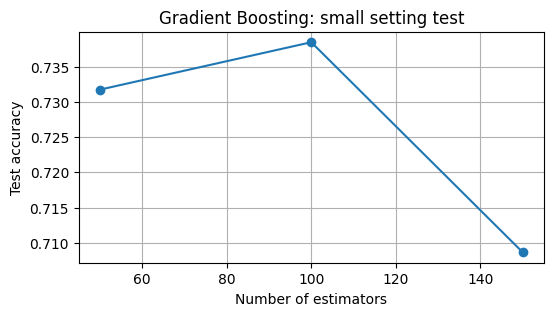

In [23]:
plt.figure(figsize=(6, 3))
plt.plot(learning_table["Estimators"], learning_table["Test accuracy"], marker="o")
plt.title("Gradient Boosting: small setting test")
plt.xlabel("Number of estimators")
plt.ylabel("Test accuracy")
plt.grid()
plt.show()

### Light Gradient Boosting

### 18. LightGBM Classifier

LightGBM is made for faster boosting. I used simple values first. `verbosity=-1` only hides long library messages.

In [24]:
# 18. LightGBM classifier
lgb_clf = Pipeline([
    ("prep", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=120,
        learning_rate=0.05,
        num_leaves=25,
        random_state=RANDOM_STATE,
        verbosity=-1
    ))
])
lgb_clf.fit(X_train, y_class_train)
lgb_class_pred = lgb_clf.predict(X_test)
lgb_class_prob = lgb_clf.predict_proba(X_test)[:, 1]
save_class_result("LightGBM Classifier", y_class_test, lgb_class_pred, lgb_class_prob)

LightGBM Classifier accuracy = 0.7308


### 19. LightGBM Regressor

In [25]:
# 19. LightGBM regressor
lgb_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=120,
        learning_rate=0.05,
        num_leaves=25,
        random_state=RANDOM_STATE,
        verbosity=-1
    ))
])
lgb_reg.fit(X_train, y_reg_train)
lgb_reg_pred = lgb_reg.predict(X_test)
save_reg_result("LightGBM Regressor", y_reg_test, lgb_reg_pred)

LightGBM Regressor MAE = 8.2089 R-square = 0.4212


### 20. Performance and training efficiency

Below I time a few LightGBM settings. Training time can change on different laptop, so this is only a simple idea. Usually more trees give more learning but also take more time.

In [26]:
# simple LightGBM speed check
lgb_speed = []
for n_tree in [50, 120, 200]:
    speed_model = Pipeline([
        ("prep", preprocessor),
        ("model", LGBMClassifier(
            n_estimators=n_tree,
            learning_rate=0.05,
            num_leaves=25,
            random_state=RANDOM_STATE,
            verbosity=-1
        ))
    ])
    start = time.perf_counter()
    speed_model.fit(X_train, y_class_train)
    seconds = time.perf_counter() - start
    acc = accuracy_score(y_class_test, speed_model.predict(X_test))
    lgb_speed.append([n_tree, seconds, acc])

lgb_speed_table = pd.DataFrame(lgb_speed, columns=["Estimators", "Train time (sec)", "Test accuracy"])
lgb_speed_table.round(4)

,Estimators,Train time (sec),Test accuracy
0,50,0.0775,0.7365
1,120,0.0940,0.7308
2,200,0.1432,0.7327


### XGBoost

### 21. XGBoost Classifier

In [27]:
# 21. XGBoost classifier
xgb_clf = Pipeline([
    ("prep", preprocessor),
    ("model", XGBClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
xgb_clf.fit(X_train, y_class_train)
xgb_class_pred = xgb_clf.predict(X_test)
xgb_class_prob = xgb_clf.predict_proba(X_test)[:, 1]
save_class_result("XGBoost Classifier", y_class_test, xgb_class_pred, xgb_class_prob)

XGBoost Classifier accuracy = 0.7365


### 22. XGBoost Regressor

In [28]:
# 22. XGBoost regressor
xgb_reg = Pipeline([
    ("prep", preprocessor),
    ("model", XGBRegressor(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
xgb_reg.fit(X_train, y_reg_train)
xgb_reg_pred = xgb_reg.predict(X_test)
save_reg_result("XGBoost Regressor", y_reg_test, xgb_reg_pred)

XGBoost Regressor MAE = 8.1316 R-square = 0.4401


### 23. Boosting model comparision

The complete result table comes in Part F. In general, AdaBoost is simple but can be affected by noisy data. Gradient Boosting is strong but can be slower. LightGBM is usually fast. XGBoost has more controls for regularization.

## Part E: Voting and Stacking Ensembles

### 24. Voting Classifier (hard voting)

For hard voting, Logistic Regression, Random Forest and Gradient Boosting each vote 0 or 1. Majority vote is final output.

In [29]:
# 24. hard voting classifier
# Every base model has own preprocessing pipeline
log_clf = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
rf_clf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
])
gb_vote_clf = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(n_estimators=80, random_state=RANDOM_STATE))
])

hard_vote = VotingClassifier(
    estimators=[("log", log_clf), ("rf", rf_clf), ("gb", gb_vote_clf)],
    voting="hard"
)
hard_vote.fit(X_train, y_class_train)
hard_pred = hard_vote.predict(X_test)
save_class_result("Hard Voting Classifier", y_class_test, hard_pred)

Hard Voting Classifier accuracy = 0.7462


### 25. Soft Voting Classifier

Soft voting averages the probabilities from models. It can be better when one model is more confident.

In [30]:
# 25. soft voting classifier
soft_vote = VotingClassifier(
    estimators=[("log", log_clf), ("rf", rf_clf), ("gb", gb_vote_clf)],
    voting="soft"
)
soft_vote.fit(X_train, y_class_train)
soft_pred = soft_vote.predict(X_test)
soft_prob = soft_vote.predict_proba(X_test)[:, 1]
save_class_result("Soft Voting Classifier", y_class_test, soft_pred, soft_prob)

Soft Voting Classifier accuracy = 0.7375


### 26. Stacking Classifier with meta-learner

I use Logistic Regression as meta-learner. It learns from predictions made by the base models.

In [31]:
# 26. stacking classifier
stack_clf = StackingClassifier(
    estimators=[("log", log_clf), ("rf", rf_clf), ("gb", gb_vote_clf)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=5,
    n_jobs=-1
)
stack_clf.fit(X_train, y_class_train)
stack_class_pred = stack_clf.predict(X_test)
stack_class_prob = stack_clf.predict_proba(X_test)[:, 1]
save_class_result("Stacking Classifier", y_class_test, stack_class_pred, stack_class_prob)

Stacking Classifier accuracy = 0.7413


### 27. Stacking Regressor for score prediction

For score prediction, final meta-model is Ridge regression. It combines the base regressor outputs.

In [32]:
# 27. stacking regressor
rf_reg = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
])
gb_stack_reg = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE))
])
tree_reg = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE))
])

stack_reg = StackingRegressor(
    estimators=[("rf", rf_reg), ("gb", gb_stack_reg), ("tree", tree_reg)],
    final_estimator=Ridge(),
    cv=5,
    n_jobs=-1
)
stack_reg.fit(X_train, y_reg_train)
stack_reg_pred = stack_reg.predict(X_test)
save_reg_result("Stacking Regressor", y_reg_test, stack_reg_pred)

Stacking Regressor MAE = 8.1909 R-square = 0.4298


## Part F: Model Evaluation and Comparision

### 28. Classification model results

In [33]:
class_table = pd.DataFrame(class_results).sort_values("F1-score", ascending=False).reset_index(drop=True)
class_table.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Hard Voting Classifier,0.7462,0.6933,0.5795,0.6313,NaN
1,XGBoost Classifier,0.7365,0.6676,0.5923,0.6277,0.7844
2,Gradient Boosting Classifier,0.7385,0.6756,0.5821,0.6253,0.7880
3,Stacking Classifier,0.7413,0.6873,0.5692,0.6227,0.7946
4,Soft Voting Classifier,0.7375,0.6778,0.5718,0.6203,0.7931
5,LightGBM Classifier,0.7308,0.6647,0.5692,0.6133,0.7841
6,AdaBoost Classifier,0.7279,0.6656,0.5513,0.6031,0.7868
7,Bagging Classifier,0.7048,0.6277,0.5231,0.5706,0.7561
8,Single Decision Tree,0.6298,0.5062,0.5256,0.5157,0.6090


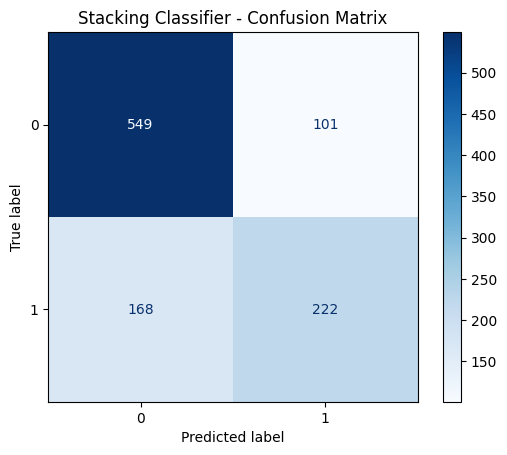

              precision    recall  f1-score   support

           0       0.77      0.84      0.80       650
           1       0.69      0.57      0.62       390

    accuracy                           0.74      1040
   macro avg       0.73      0.71      0.71      1040
weighted avg       0.74      0.74      0.74      1040



In [34]:
# confusion matrix for final stacking classifier
cm = confusion_matrix(y_class_test, stack_class_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap="Blues")
plt.title("Stacking Classifier - Confusion Matrix")
plt.show()

print(classification_report(y_class_test, stack_class_pred, zero_division=0))

### 29. Regression model results

In [35]:
reg_table = pd.DataFrame(reg_results).sort_values("R-square", ascending=False).reset_index(drop=True)
reg_table.round(4)

,Model,MAE,RMSE,R-square
0,XGBoost Regressor,8.1316,10.0955,0.4401
1,Stacking Regressor,8.1909,10.1884,0.4298
2,Gradient Boosting Regressor,8.2072,10.1998,0.4285
3,LightGBM Regressor,8.2089,10.2646,0.4212
4,Bagging Regressor,8.2934,10.3295,0.4139
5,AdaBoost Regressor,8.7095,10.6691,0.3747
6,Single Decision Tree,11.0373,13.9998,-0.0766


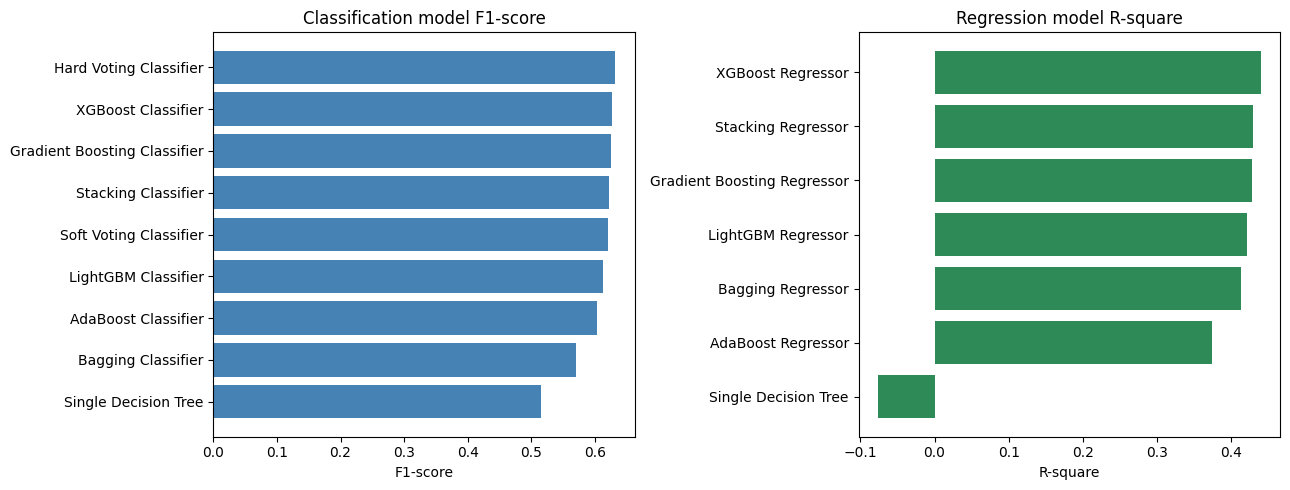

In [36]:
# simple charts make model comparision easy to see
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

show_class = class_table.sort_values("F1-score")
ax[0].barh(show_class["Model"], show_class["F1-score"], color="steelblue")
ax[0].set_title("Classification model F1-score")
ax[0].set_xlabel("F1-score")

show_reg = reg_table.sort_values("R-square")
ax[1].barh(show_reg["Model"], show_reg["R-square"], color="seagreen")
ax[1].set_title("Regression model R-square")
ax[1].set_xlabel("R-square")

plt.tight_layout()
plt.show()

### 30. Best model for each task

I select the classification model with highest F1-score and regression model with highest R-square. I also check other metrics, not only one number.

In [37]:
# 30. print best models from result tables
best_class = class_table.iloc[0]
best_reg = reg_table.iloc[0]

print("Best classification model (by F1-score):", best_class["Model"])
print("F1-score:", round(best_class["F1-score"], 4))
print("ROC-AUC:", round(best_class["ROC-AUC"], 4) if pd.notna(best_class["ROC-AUC"]) else "not available")
print()
print("Best regression model (by R-square):", best_reg["Model"])
print("R-square:", round(best_reg["R-square"], 4))
print("MAE:", round(best_reg["MAE"], 4))

Best classification model (by F1-score): Hard Voting Classifier
F1-score: 0.6313
ROC-AUC: not available

Best regression model (by R-square): XGBoost Regressor
R-square: 0.4401
MAE: 8.1316


## Part G: Final Analysis and Reporting

### 31. Final report

**Impact of bagging vs boosting**

- Bagging makes result stable by averaging many trees. It usually reduces variance.
- Boosting learns from earlier errors. It can give good score, but needs careful learning rate and number of trees.

**Comparision of tree based boosting**

- AdaBoost is easy to understand and uses weak learners.
- Gradient Boosting is flexible, but more trees can take time.
- LightGBM was made for speed and works good with many rows.
- XGBoost has extra regularization controls and is often robust.

**Voting and stacking**

- Voting is simple. It is good when different models are already available.
- Stacking can do better because a meta-model learns which base model prediction to trust.
